# Gao et al. 2021 — Breast Cancer · 04 EMT-TF Expression
Unconditional final step (outside the gate chain). EMT transcription factors scored on this
dataset, gated on detectable expression, across the Snail/Zeb/Twist/FoxC/Prrx families. The two
most pseudotime-discriminating expressed factors are overlaid as a **categorical thresholded**
expresser map on the grey manifold (house (3.5,1.5) layout).

In [ ]:
import os, sys, glob
os.environ['R_HOME'] = '/home/caleb/miniconda3/envs/scFates/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, matplotlib.pyplot as plt
from scipy.stats import spearmanr
from matplotlib.lines import Line2D
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*6)); pth_data = os.path.join(pth,'data')
pth_out = os.path.join(pth_data,'cancer','vertebrate','CCCA','Claude',cat,name)
pth_fig = os.path.join(pth,'figures','cancer','vertebrate','CCCA','Claude',cat,name)
os.makedirs(pth_fig,exist_ok=True)

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out,'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']   # house linear layout
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime', round(t.min(),2), '->', round(t.max(),2))

cells: 6605 | pseudotime 0.0 -> 11.28


## EMT-TF panel, detection-gated; derive the informative pair

In [ ]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
early = tn <= np.quantile(tn,1/3); late = tn >= np.quantile(tn,2/3)
rows=[]
for j,g in enumerate(present):
    x=X[:,j]; rho=spearmanr(tn,x).correlation
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t']).sort_values('rho_vs_t')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.05]  # robust detection floor (5%): avoids marginal expressers
early_tf = ok.iloc[0]['TF']; late_tf = ok.iloc[-1]['TF']
print(f'\nderived pair: {early_tf} (early/root) <-> {late_tf} (late/terminus)')

    TF  frac_expr  mean_early  mean_late  rho_vs_t
 PRRX2      0.119       0.091      0.091     0.023
TWIST1      0.150       0.056      0.055     0.037
 FOXC2      0.161       0.086      0.122     0.044
  ZEB1      0.014       0.005      0.015     0.044
 PRRX1      0.142       0.069      0.091     0.047
 FOXC1      0.300       0.281      0.300     0.047
 SNAI2      0.160       0.061      0.228     0.061
TWIST2      0.013       0.003      0.012     0.071
 SNAI1      0.101       0.024      0.039     0.076
  ZEB2      0.031       0.009      0.043     0.094

derived pair: PRRX2 (early/root) <-> SNAI1 (late/terminus)


## Categorical thresholded-expresser overlay (house (3.5,1.5) layout)

overlay thresholds (upper quartile among expressers): {'PRRX2': 0.842, 'SNAI1': 0.437} | cells shown: {'PRRX2': 197, 'SNAI1': 167}
PRRX2: 11.9% expressing; 197 shown; mean pseudotime of shown = 0.45 (all=0.49)
SNAI1: 10.1% expressing; 167 shown; mean pseudotime of shown = 0.54 (all=0.49)
saved expression.pdf


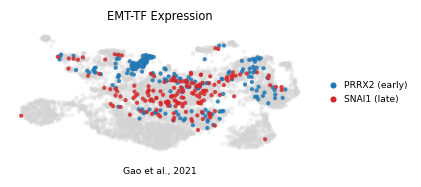

In [ ]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def _vec(g):
    x=adata[:,g].X; return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr={}
for g in [early_tf, late_tf]:
    v=_vec(g); pos=v[v>0]; thr[g]=float(np.quantile(pos,0.75)) if pos.size else 0.0
sel={g:_vec(g)>thr[g] for g in [early_tf, late_tf]}
print('overlay thresholds (upper quartile among expressers):', {g:round(thr[g],3) for g in [early_tf,late_tf]},
      '| cells shown:', {g:int(sel[g].sum()) for g in [early_tf,late_tf]})
order = sorted([early_tf, late_tf], key=lambda g: -int(sel[g].sum()))
colors = {early_tf:'tab:blue', late_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=30, alpha=.3, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=30, alpha=.85, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.legend(handles=[Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[early_tf],markersize=5,label=f'{early_tf} (early)'),
                   Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[late_tf],markersize=5,label=f'{late_tf} (late)')],
          loc='center left', bbox_to_anchor=(1.02,.5), frameon=False, fontsize=6, handletextpad=.2)
ax.set_title('EMT-TF Expression', size=7.5)
ax.text(.5,-.14,'Gao et al., 2021', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
plt.show()
for g in [early_tf, late_tf]:
    m=sel[g]; print(f'{g}: {(_vec(g)>0).mean()*100:.1f}% expressing; {int(m.sum())} shown; mean pseudotime of shown = {tn[m].mean():.2f} (all={tn.mean():.2f})')
print('saved expression.pdf')